In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy

import pynapple as nap
from neo.rawio import BlackrockRawIO

from utils import load_task_events, label, split_by

In [2]:
# 20231104 is day 2 and consisted of short blocks (20 exposure blocks x 25 sequences with 24% deviant rate, followed by 10 exposure blocks x 25 sequences with 0% deviant rate)

data_day2_path = "../../../Recordings/Silas/Data/20231104"
derivatives_path = "../../derivatives"

data_day2 = nap.EphysReader(f"{data_day2_path}/SeqPre_110423_a001.nev")  # pynapple can load nev files
behav_data_day2_matlab = scipy.io.loadmat(f"{data_day2_path}/Silas_231104_00_bhv/Silas_231104_00_bhv.mat")  # mat73 does not work on this matlab version file

In [3]:
print(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0].dtype.names)
assert np.all(behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0]['blockId'][0] == np.concatenate([np.tile(np.repeat([1, 2], 100), 10), np.zeros(1000, dtype=int)]))  # double-check that the blockID = contextID = context label for each of the 3000 trials is as expected

behav_data_day2 = behav_data_day2_matlab['bhv'][0][0]['temp_trial'][0][0][['blockId', 'seq', 'imgId', 'imgTime']]
print(behav_data_day2['seq'][0][0].shape)
print(behav_data_day2['seq'][0][0])

('numBlockPair', 'totalSeqsPerBlock', 'swapRepeats', 'swapRate', 'blockNum', 'cur_blockNum', 'blockId', 'cur_blockId', 'blockStartTime', 'blockEndTime', 'imgNum', 'cur_imgNum', 'imgId', 'imgTime', 'numTestBlocks', 'numTestSeqs', 'initialStartTime', 'seqStartTime', 'seqEndTime', 'seq', 'RewardSt', 'RewardEd', 'Eye')
(1, 25)
[[array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[5, 6, 7, 8]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[1, 2, 3, 4]], dtype=uint8) array([[1, 2, 3, 4]], dtype=uint8)
  array([[5, 6, 7, 8]], dty

In [4]:
# import mat73
# tmp = mat73.loadmat(f"{data_day2_path}/SeqPre_110423_a001.mat")
# print(tmp['NEV'])

In [5]:
data_day2

SeqPre_110423_a001
┍━━━━━━━━━━━━━━━━━━━━━━┯━━━━━━━━━━┑
│ Key                  │ Type     │
┝━━━━━━━━━━━━━━━━━━━━━━┿━━━━━━━━━━┥
│ 0:nsx3               │ TsdFrame │
│ 1:nsx4               │ TsdFrame │
│ 2:nsx6               │ TsdFrame │
│ TsGroup              │ TsGroup  │
│ 0:digital_input_port │ Ts       │
│ 1:serial_input_port  │ Ts       │
│ 2:comments           │ Ts       │
┕━━━━━━━━━━━━━━━━━━━━━━┷━━━━━━━━━━┙

In [6]:
lfp = data_day2['0:nsx3']
spikes = data_day2['TsGroup']

  index    start    end
      0       35     40
shape: (1, 2), time unit: sec.


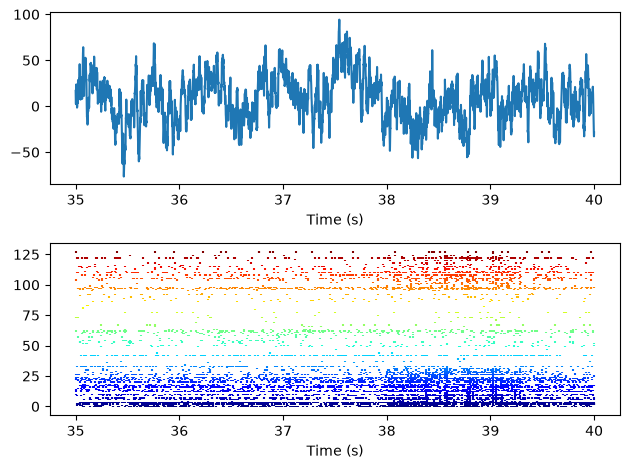

In [7]:
start, end = lfp.t[70000], lfp.t[80000]
win = nap.IntervalSet(start=start, end=end)
print(win)

lfp_win = lfp.get(start, end)
spikes_win = spikes.restrict(win)

fig = plt.figure()
ax1 = fig.add_subplot(2, 1, 1)
ax2 = fig.add_subplot(2, 1, 2)
ax1.plot(lfp_win.t, lfp_win.d[:,42])
ax1.set_xlabel("Time (s)")
colors = plt.cm.jet(np.linspace(0, 1, len(spikes)))
ax2.eventplot([spikes_win[i].t for i in spikes.keys()], colors=colors)
ax2.set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [60]:
ev = load_task_events(f"{data_day2_path}/SeqPre_110423_a001.nev")
print(ev.summary())

baseline   n=    1  total=   300.0 s
task       n=    1  total=  4166.6 s
blocks     n=   30  total=  4125.1 s
sequences  n=  750  total=  1986.0 s
reward     n=  750  total=   426.9 s
images     n= 3000  total=   750.0 s


/mnt/cup/labs/buschman/Projects/SequenceLearning/PassiveTask/decoding_RI/src/decoding_ri/utils.py:315: UserWarning: timing 'baseline': expected 300 s, measured median 300.027 s (range 300.027–300.027), 1/1 out of range
/mnt/cup/labs/buschman/Projects/SequenceLearning/PassiveTask/decoding_RI/src/decoding_ri/utils.py:315: UserWarning: timing 'soa': expected 0.4 s, measured median 0.601 s (range 0.597–1.051), 2250/2250 out of range
/mnt/cup/labs/buschman/Projects/SequenceLearning/PassiveTask/decoding_RI/src/decoding_ri/utils.py:315: UserWarning: timing 'sequence_duration': expected 1.6 s, measured median 2.419 s (range 2.407–3.909), 750/750 out of range
/mnt/cup/labs/buschman/Projects/SequenceLearning/PassiveTask/decoding_RI/src/decoding_ri/utils.py:315: UserWarning: timing 'juice_duration': expected 1 s, measured median 0.569 s (range 0.567–0.572), 750/750 out of range
/mnt/cup/labs/buschman/Projects/SequenceLearning/PassiveTask/decoding_RI/src/decoding_ri/utils.py:315: UserWarning: timi

In [85]:
from utils import check_timing
check_timing(ev)

["timing 'baseline': expected 300 s, measured median 300.027 s (range 300.027–300.027), 1/1 out of range",
 "timing 'soa': expected 0.4 s, measured median 0.601 s (range 0.597–1.051), 2250/2250 out of range",
 "timing 'sequence_duration': expected 1.6 s, measured median 2.419 s (range 2.407–3.909), 750/750 out of range",
 "timing 'juice_duration': expected 1 s, measured median 0.569 s (range 0.567–0.572), 750/750 out of range",
 "timing 'reward_delay': expected 0.6–1 s, measured median 0.819 s (range 0.618–1.018), 27/750 out of range",
 "timing 'post_sequence': expected 2–2.5 s, measured median 2.857 s (range 2.605–3.105), 720/720 out of range",
 "timing 'inter_block': expected 1.5–2.5 s, measured median 1.832 s (range 0.017–2.491), 9/29 out of range"]

In [46]:
phases = {
    "context1": lambda x: (x.block <= 20) & (x.block % 2 == 1),
    "context2": lambda x: (x.block <= 20) & (x.block % 2 == 0)
}
# img_num = {    "img1": lambda x: x.images % 4 == 0,
#     "img2": lambda x: x.images % 4 == 1,
#     "img3": lambda x: x.images % 4 == 2,
#     "img4": lambda x: x.images % 4 == 3
# }
label(ev.blocks, "context", phases)
label(ev.images, "img_num", img_num)
context_tuning = nap.compute_response_per_epoch(spikes, split_by(ev.blocks, "context"))

AttributeError: Time series object does not have the attribute images

In [53]:
ev.images

Time (s)
------------------  ----
321.68086666666665     1
322.2776               2
322.8785               3
323.4789               4
326.74756666666667     5
327.34883333333335     6
327.9489               7
...
4476.0817           2994
4476.682766666667   2995
4477.283266666666   2996
4480.7355333333335  2997
4481.3361           2998
4481.937            2999
4482.537266666666   3000
dtype: int64, shape: (3000,)

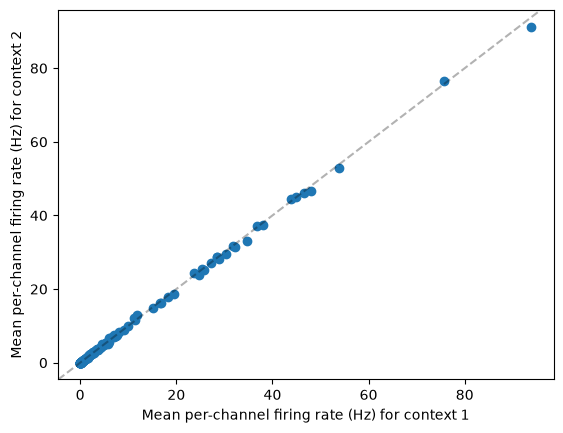

In [24]:
plt.scatter(context_tuning[:,0],context_tuning[:,1])
plt.axline((0, 0), slope=1, color='black', linestyle='--', alpha=.3)
plt.xlabel('Mean per-channel firing rate (Hz) for context 1')
plt.ylabel('Mean per-channel firing rate (Hz) for context 2')
plt.show()

In [39]:
split_by(ev.blocks, "context")['context1']

  index     start       end    block  context
      0   321.603   454.096        1  context1
      1   588.271   719.525        3  context1
      2   853.427   985.026        5  context1
      3  1118.41   1256.14         7  context1
      4  1422.06   1572.41         9  context1
      5  1735.41   1899.67        11  context1
      6  2063.85   2217.37        13  context1
      7  2351.18   2483.55        15  context1
      8  2616.45   2749.08        17  context1
      9  2883.55   3015.38        19  context1
shape: (10, 2), time unit: sec.

In [59]:
behav_data_day2_matlab['bhv'][0][0]['opts'][0][0]['displayDuration']

array([[0.25]])